In [1]:
import pandas as pd 
import matplotlib.pyplot as plt  
import seaborn as sns 
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

In [2]:
df = pd.read_csv('retail_store_inventory.csv', parse_dates=True)

In [3]:
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [4]:
df.describe()

,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
count,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,0.497305,55.146077
std,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,0.499996,26.191408
min,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,0.000000,5.030000
25%,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,0.000000,32.680000
50%,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,0.000000,55.010000
75%,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,1.000000,77.820000
max,500.000000,499.000000,200.000000,518.550000,100.000000,20.000000,1.000000,104.940000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  str    
 1   Store ID            73100 non-null  str    
 2   Product ID          73100 non-null  str    
 3   Category            73100 non-null  str    
 4   Region              73100 non-null  str    
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  str    
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  str    
dtypes: float64(3), int64(5), str(7)
memory usage: 11.4 MB


In [6]:
# import sys, subprocess
# subprocess.check_call([sys.executable, "-m", "pip", "install", "seaborn"])

# def create_time_features(df, label=None):
#     df = df.copy()
#     df['date'] = df['Date']
#     df['hour'] = df['Date'].dt.hour
#     df['dayofweek'] = df['Date'].dt.dayofweek
#     df['quater'] = df['Date'].dt.quarter
#     df['month'] = df['Date'].dt.month
#     df['year'] = df['Date'].dt.year
#     df['dayofyear'] = df['Date'].dt.dayofyear
#     df['weekofyear'] = df['Date'].dt.isocalendar().week

#     X = df[['date', 'hour', 'dayofweek', 'quater', 'month', 
#             'year', 'dayofyear', 'dayofyear', 'weekofyear']]
    
#     if label:
#         y = df[label]
#         return X, y
#     return X

# X, y = create_time_features(df, label='Demand Forecast')

PROPHET MODEL:

In [7]:
df = df.drop(columns={'Units Sold'})

In [8]:
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [9]:
df_prophet = df.copy()

df_prophet.index = pd.to_datetime(df_prophet['Date'])

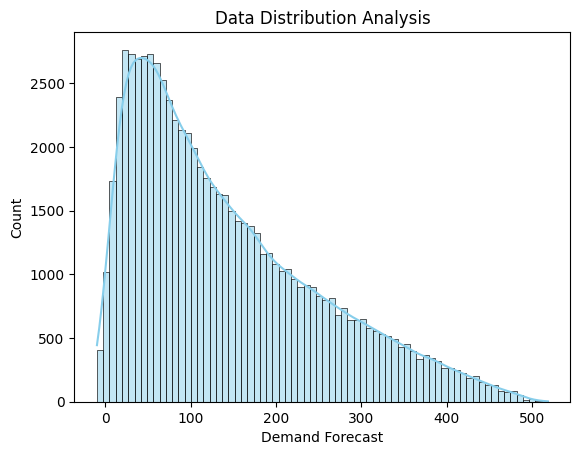

In [10]:
df_prophet = df_prophet.drop(columns='Date')

demand_fcst_dist = df_prophet['Demand Forecast']

sns.histplot(demand_fcst_dist, kde=True, color="skyblue", bins='auto')

# Customize the chart
plt.title("Data Distribution Analysis")

# Display the plot
plt.show()

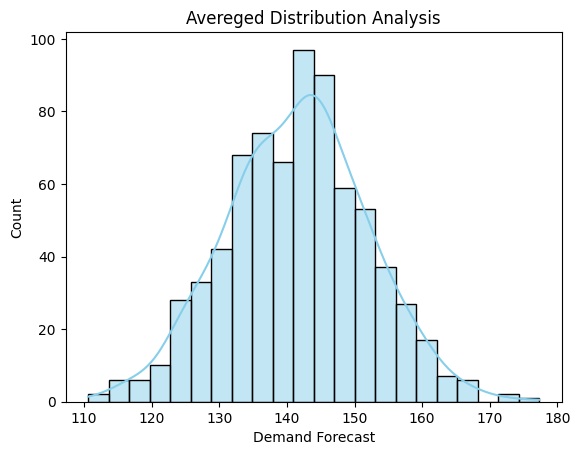

In [11]:

demand_fcst_dist = df_prophet.groupby('Date')['Demand Forecast'].mean()

sns.histplot(demand_fcst_dist, kde=True, color="skyblue", bins='auto')

# Customize the chart
plt.title("Avereged Distribution Analysis")

# Display the plot
plt.show()

In [12]:
len(df_prophet['Product ID'].unique())
dates = df_prophet.index

In [13]:
season_encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
season_columns = season_encoder.fit_transform(df_prophet[['Seasonality']])

region_encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
region_columns = region_encoder.fit_transform(df_prophet[['Region']])

szn_encoded_df = pd.DataFrame(
    season_columns,
    index=df_prophet.index,
    columns=season_encoder.get_feature_names_out(['Seasonality'])
)

region_encoded_df = pd.DataFrame(
    region_columns,
    index=df_prophet.index,
    columns=region_encoder.get_feature_names_out(['Region'])
)

In [14]:
df_prophet = pd.concat([df_prophet, szn_encoded_df, region_encoded_df], axis=1)

In [15]:
df_prophet[['Seasonality_Autumn', 'Seasonality_Spring', 'Seasonality_Summer']] = df_prophet[['Seasonality_Autumn', 'Seasonality_Spring', 'Seasonality_Summer']].astype('int32')

In [16]:
df_prophet = df_prophet.drop(columns=['Seasonality'])

In [17]:
df_prophet = df_prophet.reset_index()
indices_2022 = df_prophet.index[df['Date'] == '2022-01-01']
indices_2023 = df_prophet.index[df['Date'] == '2023-01-01']


In [18]:
# df_prophet = pd.get_dummies(df_prophet, columns=['Store ID'])
df_prophet = pd.get_dummies(df_prophet, columns=['Category'])
df_prophet = pd.get_dummies(df_prophet, columns=['Region'])
df_prophet = pd.get_dummies(df_prophet, columns=['Weather Condition'])
df_prophet = df_prophet.drop(columns=['Product ID'])

In [19]:
df_2022 = df_prophet.iloc[:36499]
df_2023 = df_prophet.iloc[36500:]

In [20]:
df_2022['Date'] = pd.to_datetime(df_2022['Date'])
df_2023['Date'] = pd.to_datetime(df_2023['Date'])

df_2022['quarter_number'] = df_2022['Date'].dt.quarter
df_2023['quarter_number'] = df_2023['Date'].dt.quarter

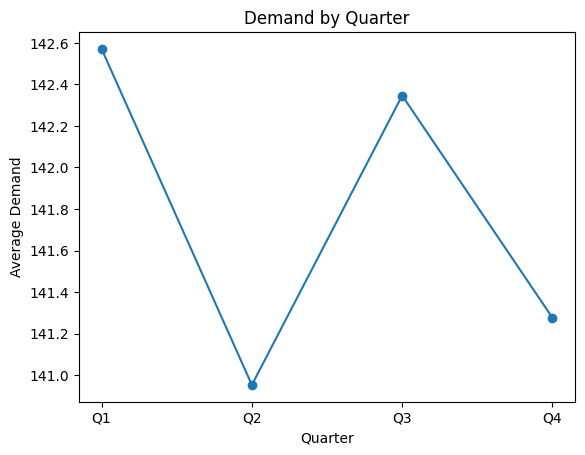

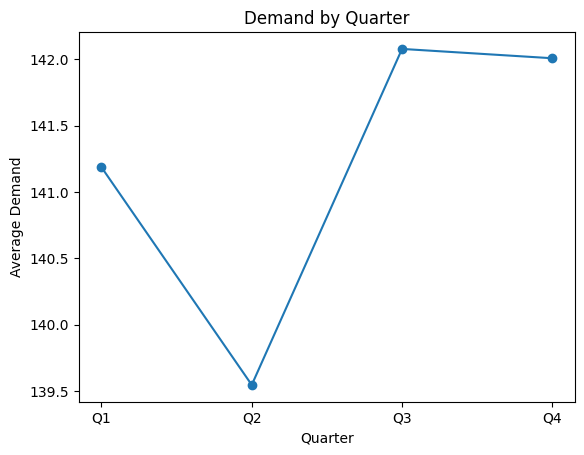

In [21]:
quarter_summary = df_2022.groupby('quarter_number')['Demand Forecast'].mean()

plt.plot(quarter_summary.index, quarter_summary.values, marker='o')
plt.xticks([1, 2, 3, 4], ['Q1', 'Q2', 'Q3', 'Q4'])
plt.xlabel('Quarter')
plt.ylabel('Average Demand')
plt.title('Demand by Quarter')
plt.show()

quarter_summary_2023 = df_2023.groupby('quarter_number')['Demand Forecast'].mean()

plt.plot(quarter_summary_2023.index, quarter_summary_2023.values, marker='o')
plt.xticks([1, 2, 3, 4], ['Q1', 'Q2', 'Q3', 'Q4'])
plt.xlabel('Quarter')
plt.ylabel('Average Demand')
plt.title('Demand by Quarter')
plt.show()


FINAL MODEL CLEANING AND PREP BEFORE MODEL CREATION

In [22]:
emregency_df = df_prophet.copy()

df_prophet = df_prophet.rename(columns={'Date': 'ds'})
df_prophet = df_prophet.rename(columns={'Demand Forecast': 'y'})
df_prophet['hour'] = df_prophet['ds'].dt.hour
df_prophet['dayofweek'] = df_prophet['ds'].dt.dayofweek
df_prophet['quater'] = df_prophet['ds'].dt.quarter
df_prophet['month'] = df_prophet['ds'].dt.month
df_prophet['year'] = df_prophet['ds'].dt.year
df_prophet['dayofyear'] = df_prophet['ds'].dt.dayofyear
df_prophet['weekofyear'] = df_prophet['ds'].dt.isocalendar().week

In [23]:
df_S001 = df_prophet[df_prophet['Store ID'] == 'S001']
df_S002 = df_prophet[df_prophet['Store ID'] == 'S002']
df_S003 = df_prophet[df_prophet['Store ID'] == 'S003']
df_S004 = df_prophet[df_prophet['Store ID'] == 'S004']
df_S005 = df_prophet[df_prophet['Store ID'] == 'S005']

<Axes: >

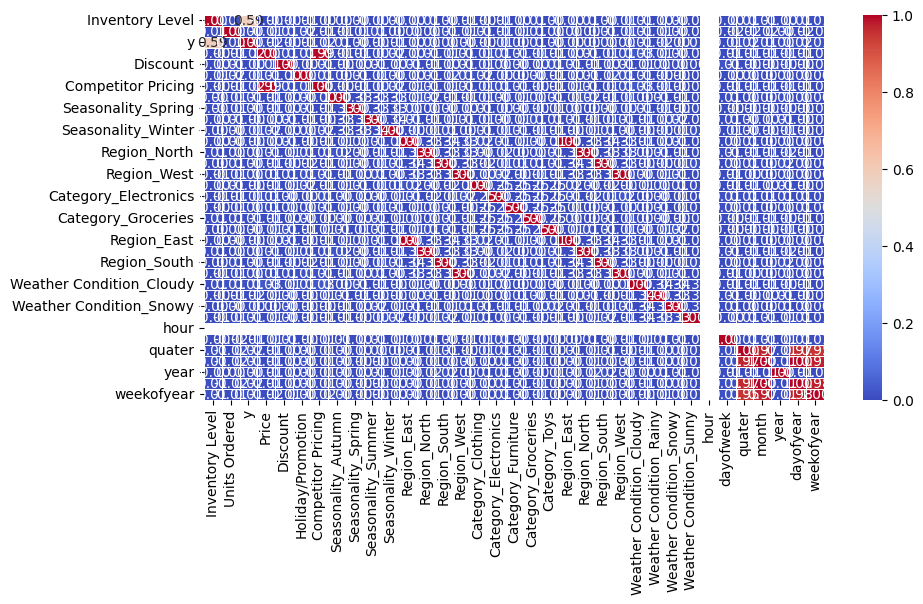

In [24]:
# plotting a correlation matrix to see if we have any columns that dont add much information
# This will, ofcourse, remain the same for all dataframes. So I will only create one matrix
df_corr = df_S001.corr(numeric_only=True)

plt.figure(figsize=(10, 5))

sns.heatmap(
    df_corr,
    annot=True,  # Shows the numerical correlation value in each cell
    cmap="coolwarm",  # Colors range from blue (negative) to red (positive)
    vmin=0,  # Sets the color scale minimum
    vmax=1,  # Sets the color scale maximum
    fmt=".2f",  # Rounds numbers to 2 decimal places
    linewidths=0.5,  # Adds thin white borders between the cells
)


In [25]:
# High correlation between both competitor pricing and Price. As a result I will drop one. 
df_S001 = df_S001.drop(columns=['Competitor Pricing'])
df_S002 = df_S002.drop(columns=['Competitor Pricing'])
df_S003 = df_S003.drop(columns=['Competitor Pricing'])
df_S004 = df_S004.drop(columns=['Competitor Pricing'])
df_S005 = df_S005.drop(columns=['Competitor Pricing'])

In [26]:
df_S001.head()

,ds,Store ID,Inventory Level,Units Ordered,y,Price,Discount,Holiday/Promotion,Seasonality_Autumn,Seasonality_Spring,...,Weather Condition_Rainy,Weather Condition_Snowy,Weather Condition_Sunny,hour,dayofweek,quater,month,year,dayofyear,weekofyear
0,2022-01-01,S001,231,55,135.47,33.50,20,0,1,0,...,True,False,False,0,5,1,1,2022,1,52
1,2022-01-01,S001,204,66,144.04,63.01,20,0,1,0,...,False,False,True,0,5,1,1,2022,1,52
2,2022-01-01,S001,102,51,74.02,27.99,10,1,0,0,...,False,False,True,0,5,1,1,2022,1,52
3,2022-01-01,S001,469,164,62.18,32.72,10,1,1,0,...,False,False,False,0,5,1,1,2022,1,52
4,2022-01-01,S001,166,135,9.26,73.64,0,0,0,0,...,False,False,True,0,5,1,1,2022,1,52


In [27]:

# S001_X = df_S001.drop(columns=['y'])
# S001_y = df_S001['y']

# S002_X = df_S002.drop(columns=['y'])
# S002_y = df_S002['y']

# S003_X = df_S003.drop(columns=['y'])
# S003_y = df_S003['y']

# S004_X = df_S004.drop(columns=['y'])
# S004_y = df_S004['y']

# S005_X = df_S005.drop(columns=['y'])
# S005_y = df_S005['y']

# S001_X_train, S001_X_test, S001_y_train, S001_y_test = train_test_split(S001_X, S001_y, test_size=0.2, random_state=42)
# S002_X_train, S002_X_test, S002_y_train, S002_y_test = train_test_split(S002_X, S002_y, test_size=0.2, random_state=42)
# S003_X_train, S003_X_test, S003_y_train, S003_y_test = train_test_split(S003_X, S003_y, test_size=0.2, random_state=42)
# S004_X_train, S004_X_test, S004_y_train, S004_y_test = train_test_split(S004_X, S004_y, test_size=0.2, random_state=42)
# S005_X_train, S005_X_test, S005_y_train, S005_y_test = train_test_split(S005_X, S005_y, test_size=0.2, random_state=42)


In [28]:
import sys, subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "prophet"])

0

In [29]:
from prophet import Prophet

model = Prophet()

c:\Users\sachi\.virtualenvs\housePredict-tswQvzyo\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


In [30]:
for col_name in df_S001.columns:
    if col_name not in ['ds', 'y']:
        model.add_regressor(col_name)

In [31]:
# %time
# model.fit(df_S001)
# model.fit(df_S002)
# model.fit(df_S003)
# model.fit(df_S004)
# model.fit(df_S005)

In [32]:
df_S001

,ds,Store ID,Inventory Level,Units Ordered,y,Price,Discount,Holiday/Promotion,Seasonality_Autumn,Seasonality_Spring,...,Weather Condition_Rainy,Weather Condition_Snowy,Weather Condition_Sunny,hour,dayofweek,quater,month,year,dayofyear,weekofyear
0,2022-01-01,S001,231,55,135.47,33.50,20,0,1,0,...,True,False,False,0,5,1,1,2022,1,52
1,2022-01-01,S001,204,66,144.04,63.01,20,0,1,0,...,False,False,True,0,5,1,1,2022,1,52
2,2022-01-01,S001,102,51,74.02,27.99,10,1,0,0,...,False,False,True,0,5,1,1,2022,1,52
3,2022-01-01,S001,469,164,62.18,32.72,10,1,1,0,...,False,False,False,0,5,1,1,2022,1,52
4,2022-01-01,S001,166,135,9.26,73.64,0,0,0,0,...,False,False,True,0,5,1,1,2022,1,52
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73015,2024-01-01,S001,74,189,27.53,40.61,10,1,0,0,...,False,False,False,0,0,1,1,2024,1,1
73016,2024-01-01,S001,282,61,201.40,20.68,0,0,0,0,...,True,False,False,0,0,1,1,2024,1,1
73017,2024-01-01,S001,191,95,25.01,24.10,5,1,0,0,...,False,False,False,0,0,1,1,2024,1,1
73018,2024-01-01,S001,149,85,154.83,81.71,20,0,0,1,...,False,False,True,0,0,1,1,2024,1,1


In [33]:
# df_S001[['Region_South', 'Region_West', 'Region_North']] = df_S001[['Region_South', 'Region_West', 'Region_North']].replace(['True'], 1)
# df_S002[['Region_South', 'Region_West', 'Region_North']] = df_S002[['Region_South', 'Region_West', 'Region_North']].replace(['True'], 1)
# df_S003[['Region_South', 'Region_West', 'Region_North']] = df_S003[['Region_South', 'Region_West', 'Region_North']].replace(['True'], 1)
# df_S004[['Region_South', 'Region_West', 'Region_North']] = df_S004[['Region_South', 'Region_West', 'Region_North']].replace(['True'], 1)
# df_S005[['Region_South', 'Region_West', 'Region_North']] = df_S005[['Region_South', 'Region_West', 'Region_North']].replace(['True'], 1)

# df_S001[['Region_South', 'Region_West', 'Region_North']] = df_S001[['Region_South', 'Region_West', 'Region_North']].replace(['False'], 0)
# df_S002[['Region_South', 'Region_West', 'Region_North']] = df_S002[['Region_South', 'Region_West', 'Region_North']].replace(['False'], 0)
# df_S003[['Region_South', 'Region_West', 'Region_North']] = df_S003[['Region_South', 'Region_West', 'Region_North']].replace(['False'], 0)
# df_S004[['Region_South', 'Region_West', 'Region_North']] = df_S004[['Region_South', 'Region_West', 'Region_North']].replace(['False'], 0)
# df_S005[['Region_South', 'Region_West', 'Region_North']] = df_S005[['Region_South', 'Region_West', 'Region_North']].replace(['False'], 0)


df_S001 = df_S001.loc[:, ~df_S001.columns.duplicated()]
df_S002 = df_S002.loc[:, ~df_S002.columns.duplicated()]
df_S003 = df_S003.loc[:, ~df_S003.columns.duplicated()]
df_S004 = df_S004.loc[:, ~df_S004.columns.duplicated()]
df_S005 = df_S005.loc[:, ~df_S005.columns.duplicated()]
cols = [
    'Region_South', 'Region_West', 'Region_North',
    'Weather Condition_Rainy', 'Weather Condition_Snowy',
    'Weather Condition_Sunny'
]

for dataframe in [df_S001, df_S002, df_S003, df_S004, df_S005]:
    dataframe = dataframe.loc[:, ~dataframe.columns.duplicated()]
    dataframe[cols] = dataframe[cols].astype(int)


In [34]:
df_S001.info()

<class 'pandas.DataFrame'>
Index: 14620 entries, 0 to 73019
Data columns (total 32 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   ds                        14620 non-null  datetime64[us]
 1   Store ID                  14620 non-null  str           
 2   Inventory Level           14620 non-null  int64         
 3   Units Ordered             14620 non-null  int64         
 4   y                         14620 non-null  float64       
 5   Price                     14620 non-null  float64       
 6   Discount                  14620 non-null  int64         
 7   Holiday/Promotion         14620 non-null  int64         
 8   Seasonality_Autumn        14620 non-null  int32         
 9   Seasonality_Spring        14620 non-null  int32         
 10  Seasonality_Summer        14620 non-null  int32         
 11  Seasonality_Winter        14620 non-null  float64       
 12  Region_East               14620 no

In [35]:
df_S001[['Region_South', 'Region_West', 'Region_North']].head()

,Region_South,Region_West,Region_North
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,1.0,0.0
3,0.0,0.0,1.0
4,0.0,0.0,0.0


In [36]:
# for df in [df_S001, df_S002, df_S003, df_S004, df_S005]:
#     bool_cols = [c for c in df.columns if df[c].dtype == 'bool']
#     df.drop(columns=bool_cols, inplace=True)

In [37]:
def clean_frame(frame):
    frame = frame.loc[:, ~frame.columns.duplicated()]  # remove duplicate columns
    bool_cols = [col for col in frame.columns if frame[col].dtype == 'bool']
    return frame.drop(columns=bool_cols)

df_S001 = clean_frame(df_S001)
df_S002 = clean_frame(df_S002)
df_S003 = clean_frame(df_S003)
df_S004 = clean_frame(df_S004)
df_S005 = clean_frame(df_S005)

In [38]:
df_S001 = df_S001.drop(columns=['year'])
df_S002 = df_S002.drop(columns=['year'])
df_S003 = df_S003.drop(columns=['year'])
df_S004 = df_S004.drop(columns=['year'])
df_S005 = df_S005.drop(columns=['year'])

df_S001 = df_S001.drop(columns=['Store ID'])
df_S002 = df_S002.drop(columns=['Store ID'])
df_S003 = df_S003.drop(columns=['Store ID'])
df_S004 = df_S004.drop(columns=['Store ID'])
df_S005 = df_S005.drop(columns=['Store ID'])

cols = [column for column in df_S001.columns]

df_S001_prophet = df_S001.groupby('ds')[cols].mean()
df_S002_prophet = df_S002.groupby('ds')[cols].mean()
df_S003_prophet = df_S003.groupby('ds')[cols].mean()
df_S004_prophet = df_S004.groupby('ds')[cols].mean()
df_S005_prophet = df_S005.groupby('ds')[cols].mean()

In [39]:
from prophet.diagnostics import cross_validation, performance_metrics

# 1. Create a dictionary of your dataframes (e.g., different stores or products)
datasets = {
    'Store_S001': df_S001, 
    'Store_S002': df_S002, 
    'Store_S003': df_S003, 
    'Store_S004': df_S004, 
    'Store_S005': df_S005, 
}

# Empty structures to hold our results
fitted_models = {}
all_performance_results = []

# 2. Loop through each dataset
for name, df in datasets.items():
    %time
    print(f"Training and evaluating model for: {name}...")
    
    # Initialize a FRESH model for this specific dataset
    model = Prophet()
    model.fit(df)
    
    # Save the fitted model into our dictionary for later use/forecasting
    fitted_models[name] = model
    
    # 3. Run cross-validation (Adjust horizons based on your data)
    df_cv = cross_validation(
        model, 
        initial='584 days', 
        period='30 days', 
        horizon='30 days',
        disable_tqdm=True
    )
    
    # 4. Calculate metrics
    df_p = performance_metrics(df_cv)
    
    # 5. Extract the average error across the entire forecast horizon
    # (or choose a specific horizon row like df_p.iloc[-1])
    avg_metrics = df_p.mean(numeric_only=True).to_dict()
    avg_metrics['Dataset'] = name  # Label the row
    
    all_performance_results.append(avg_metrics)

# 6. Combine all metrics into a single comparison table
df_comparison = pd.DataFrame(all_performance_results).set_index('Dataset')


CPU times: total: 0 ns
Wall time: 6.91 μs
Training and evaluating model for: Store_S001...


20:43:48 - cmdstanpy - INFO - Chain [1] start processing
20:43:49 - cmdstanpy - INFO - Chain [1] done processing
20:43:50 - cmdstanpy - INFO - Chain [1] start processing
20:43:51 - cmdstanpy - INFO - Chain [1] done processing
20:43:52 - cmdstanpy - INFO - Chain [1] start processing
20:43:53 - cmdstanpy - INFO - Chain [1] done processing
20:43:53 - cmdstanpy - INFO - Chain [1] start processing
20:43:54 - cmdstanpy - INFO - Chain [1] done processing
20:43:55 - cmdstanpy - INFO - Chain [1] start processing
20:43:56 - cmdstanpy - INFO - Chain [1] done processing


CPU times: total: 0 ns
Wall time: 4.29 μs
Training and evaluating model for: Store_S002...


20:43:57 - cmdstanpy - INFO - Chain [1] start processing
20:43:59 - cmdstanpy - INFO - Chain [1] done processing
20:43:59 - cmdstanpy - INFO - Chain [1] start processing
20:44:00 - cmdstanpy - INFO - Chain [1] done processing
20:44:01 - cmdstanpy - INFO - Chain [1] start processing
20:44:02 - cmdstanpy - INFO - Chain [1] done processing
20:44:03 - cmdstanpy - INFO - Chain [1] start processing
20:44:04 - cmdstanpy - INFO - Chain [1] done processing
20:44:06 - cmdstanpy - INFO - Chain [1] start processing
20:44:07 - cmdstanpy - INFO - Chain [1] done processing


CPU times: total: 0 ns
Wall time: 8.58 μs
Training and evaluating model for: Store_S003...


20:44:09 - cmdstanpy - INFO - Chain [1] start processing
20:44:11 - cmdstanpy - INFO - Chain [1] done processing
20:44:12 - cmdstanpy - INFO - Chain [1] start processing
20:44:13 - cmdstanpy - INFO - Chain [1] done processing
20:44:14 - cmdstanpy - INFO - Chain [1] start processing
20:44:14 - cmdstanpy - INFO - Chain [1] done processing
20:44:15 - cmdstanpy - INFO - Chain [1] start processing
20:44:17 - cmdstanpy - INFO - Chain [1] done processing
20:44:18 - cmdstanpy - INFO - Chain [1] start processing
20:44:19 - cmdstanpy - INFO - Chain [1] done processing


CPU times: total: 0 ns
Wall time: 5.48 μs
Training and evaluating model for: Store_S004...


20:44:20 - cmdstanpy - INFO - Chain [1] start processing
20:44:22 - cmdstanpy - INFO - Chain [1] done processing
20:44:23 - cmdstanpy - INFO - Chain [1] start processing
20:44:24 - cmdstanpy - INFO - Chain [1] done processing
20:44:25 - cmdstanpy - INFO - Chain [1] start processing
20:44:27 - cmdstanpy - INFO - Chain [1] done processing
20:44:28 - cmdstanpy - INFO - Chain [1] start processing
20:44:30 - cmdstanpy - INFO - Chain [1] done processing
20:44:30 - cmdstanpy - INFO - Chain [1] start processing
20:44:32 - cmdstanpy - INFO - Chain [1] done processing


CPU times: total: 0 ns
Wall time: 4.77 μs
Training and evaluating model for: Store_S005...


20:44:33 - cmdstanpy - INFO - Chain [1] start processing
20:44:34 - cmdstanpy - INFO - Chain [1] done processing
20:44:35 - cmdstanpy - INFO - Chain [1] start processing
20:44:37 - cmdstanpy - INFO - Chain [1] done processing
20:44:37 - cmdstanpy - INFO - Chain [1] start processing
20:44:38 - cmdstanpy - INFO - Chain [1] done processing
20:44:39 - cmdstanpy - INFO - Chain [1] start processing
20:44:39 - cmdstanpy - INFO - Chain [1] done processing
20:44:40 - cmdstanpy - INFO - Chain [1] start processing
20:44:41 - cmdstanpy - INFO - Chain [1] done processing


LSTM DATA PREP AND MODELLING:

In [40]:
# # df_S001_lstm = df_S001.drop(columns=['ds'])
# df_S001_lstm = df_S001.groupby('ds')[cols].mean().reset_index()

# # df_S002_lstm = df_S002.drop(columns=['ds'])
# df_S002_lstm = df_S002.groupby('ds')[cols].mean().reset_index()

# # df_S003_lstm = df_S003.drop(columns=['ds'])
# df_S003_lstm = df_S003.groupby('ds')[cols].mean().reset_index()

# # df_S004_lstm = df_S004.drop(columns=['ds'])
# df_S004_lstm = df_S004.groupby('ds')[cols].mean().reset_index()

# # df_S005_lstm = df_S005.drop(columns=['ds'])
# df_S005_lstm = df_S005.groupby('ds')[cols].mean().reset_index()

# Exclude 'ds' and 'y' from aggregation columns
features_for_lstm = [c for c in cols if c not in ['ds', 'y']]

df_S001_lstm = df_S001.groupby('ds')[features_for_lstm + ['y']].mean().reset_index()
df_S002_lstm = df_S002.groupby('ds')[features_for_lstm + ['y']].mean().reset_index()
df_S003_lstm = df_S003.groupby('ds')[features_for_lstm + ['y']].mean().reset_index()
df_S004_lstm = df_S004.groupby('ds')[features_for_lstm + ['y']].mean().reset_index()
df_S005_lstm = df_S005.groupby('ds')[features_for_lstm + ['y']].mean().reset_index()

df_S001_lstm = df_S001_lstm.drop(columns=['ds'])
df_S002_lstm = df_S002_lstm.drop(columns=['ds'])
df_S003_lstm = df_S003_lstm.drop(columns=['ds'])
df_S004_lstm = df_S004_lstm.drop(columns=['ds'])
df_S005_lstm = df_S005_lstm.drop(columns=['ds'])

In [41]:
df_S001_lstm.describe()

,Inventory Level,Units Ordered,Price,Discount,Holiday/Promotion,Seasonality_Autumn,Seasonality_Spring,Seasonality_Summer,Seasonality_Winter,Region_East,Region_North,Region_South,Region_West,hour,dayofweek,quater,month,dayofyear,weekofyear,y
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.0,731.000000,731.000000,731.000000,731.000000,731.0,731.000000
mean,273.339945,110.388304,55.112079,9.921683,0.494665,0.248085,0.247059,0.251778,0.253078,0.251368,0.248769,0.250547,0.249316,0.0,3.002736,2.507524,6.518468,182.751026,26.534884,140.144895
std,27.804054,11.741796,5.962861,1.599691,0.109132,0.098184,0.098211,0.097346,0.101026,0.096505,0.096826,0.097852,0.095154,0.0,2.004787,1.118162,3.453904,105.580838,15.076602,24.074968
min,175.350000,69.200000,37.709500,5.250000,0.100000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.050000,0.0,0.000000,1.000000,1.000000,1.000000,1.0,71.540500
25%,253.850000,102.350000,50.987250,8.750000,0.450000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.0,1.000000,2.000000,4.000000,91.500000,13.5,124.338250
50%,273.300000,110.650000,55.173500,10.000000,0.500000,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000,0.0,3.000000,3.000000,7.000000,183.000000,27.0,139.696000
75%,292.775000,118.450000,59.356000,11.000000,0.550000,0.300000,0.300000,0.300000,0.300000,0.300000,0.300000,0.300000,0.300000,0.0,5.000000,4.000000,10.000000,274.000000,40.0,156.068750
max,344.750000,146.500000,73.989500,15.000000,0.800000,0.600000,0.550000,0.550000,0.600000,0.550000,0.550000,0.600000,0.550000,0.0,6.000000,4.000000,12.000000,365.000000,52.0,221.072500


Creating training and test split 

In [42]:


def train_test_scale_df(df):
    target_scaler = MinMaxScaler(feature_range=(0, 1))
    features = [c for c in df.columns if c != 'y']
    target = 'y'

    train_size = int(len(df) * 0.8)
    train_df = df.iloc[:train_size].copy()
    test_df = df.iloc[train_size:].copy()

    scaler = MinMaxScaler(feature_range=(0, 1))
    scaler.fit(train_df[features])

    train_scaled = scaler.transform(train_df[features])
    test_scaled = scaler.transform(test_df[features])

    train_df[features] = train_scaled
    test_df[features] = test_scaled

    target_scaler.fit(train_df[[target]])

    train_y_scaled = target_scaler.transform(train_df[[target]])
    test_y_scaled = target_scaler.transform(test_df[[target]])

    train_df[[target]] = train_y_scaled
    test_df[[target]] = test_y_scaled

    return train_df, test_df, train_y_scaled, test_y_scaled, target_scaler 

S001_train_df, S001_test_df, S001_train_y_scaled, S001_test_y_scaled, S001_scaler = train_test_scale_df(df_S001_lstm)
S002_train_df, S002_test_df, S002_train_y_scaled, S002_test_y_scaled, S002_scaler  = train_test_scale_df(df_S002_lstm)
S003_train_df, S003_test_df, S003_train_y_scaled, S003_test_y_scaled, S003_scaler  = train_test_scale_df(df_S003_lstm)
S004_train_df, S004_test_df, S004_train_y_scaled, S004_test_y_scaled, S004_scaler  = train_test_scale_df(df_S004_lstm)
S005_train_df, S005_test_df, S005_train_y_scaled, S005_test_y_scaled, S005_scaler  = train_test_scale_df(df_S005_lstm)

In [43]:
S001_y = S001_train_df['y']
S002_y = S002_train_df['y']
S003_y = S003_train_df['y']
S004_y = S004_train_df['y']
S005_y = S005_train_df['y']

S001_train_df = S001_train_df.drop(columns=['y'])
S002_train_df = S002_train_df.drop(columns=['y'])
S003_train_df = S003_train_df.drop(columns=['y'])
S004_train_df = S004_train_df.drop(columns=['y'])
S005_train_df = S005_train_df.drop(columns=['y'])

In [44]:
TIME_STEPS = 30

def reshape_dataframe(dataframe, y_series):
    # Extract raw 2D values from your DataFrames
    # The dataframe should already have 'y' column removed
    X_raw = dataframe.values  # Shape: (total_rows, num_features)
    y_raw = y_series.to_numpy()            # Shape: (total_rows,)

    # Build the 3D sliding windows for X
    # We want enough X windows to pair with y values
    # If we have N total samples, we can create N - TIME_STEPS windows
    # because the first window needs TIME_STEPS samples to look back
    num_samples = len(X_raw) - TIME_STEPS
    
    X_lstm = np.lib.stride_tricks.sliding_window_view(
        X_raw, 
        window_shape=(TIME_STEPS, X_raw.shape[1])
    ).squeeze(axis=1)[:num_samples]  # Limit to num_samples windows

    # Align the y targets
    # Window i (rows [i:i+30]) predicts y at index i+30
    # So we take y values from index TIME_STEPS to TIME_STEPS + num_samples
    y_lstm = y_raw[TIME_STEPS:TIME_STEPS + num_samples]

    # Sanity Check to confirm alignment
    print("--- Final Reshaped Arrays for LSTM ---")
    print(f"X_lstm shape (samples, time_steps, features): {X_lstm.shape}")
    print(f"y_lstm shape (samples,):                     {y_lstm.shape}")

    # Ensure the sample counts match perfectly
    assert X_lstm.shape[0] == y_lstm.shape[0], "Error: Sample mismatch between X and y!"

    return X_lstm, y_lstm

X_S001_lstm, y_S001_lstm = reshape_dataframe(S001_train_df, S001_y)
X_S002_lstm, y_S002_lstm = reshape_dataframe(S002_train_df, S002_y)
X_S003_lstm, y_S003_lstm = reshape_dataframe(S003_train_df, S003_y)
X_S004_lstm, y_S004_lstm = reshape_dataframe(S004_train_df, S004_y)
X_S005_lstm, y_S005_lstm = reshape_dataframe(S005_train_df, S005_y)

--- Final Reshaped Arrays for LSTM ---
X_lstm shape (samples, time_steps, features): (554, 30, 19)
y_lstm shape (samples,):                     (554,)
--- Final Reshaped Arrays for LSTM ---
X_lstm shape (samples, time_steps, features): (554, 30, 19)
y_lstm shape (samples,):                     (554,)
--- Final Reshaped Arrays for LSTM ---
X_lstm shape (samples, time_steps, features): (554, 30, 19)
y_lstm shape (samples,):                     (554,)
--- Final Reshaped Arrays for LSTM ---
X_lstm shape (samples, time_steps, features): (554, 30, 19)
y_lstm shape (samples,):                     (554,)
--- Final Reshaped Arrays for LSTM ---
X_lstm shape (samples, time_steps, features): (554, 30, 19)
y_lstm shape (samples,):                     (554,)


In [45]:
print("S001_train_df shape:", S001_train_df.shape)
print("S001_y length:", len(S001_y))
print("S001_train_df columns:", S001_train_df.columns.tolist())

S001_train_df shape: (584, 19)
S001_y length: 584
S001_train_df columns: ['Inventory Level', 'Units Ordered', 'Price', 'Discount', 'Holiday/Promotion', 'Seasonality_Autumn', 'Seasonality_Spring', 'Seasonality_Summer', 'Seasonality_Winter', 'Region_East', 'Region_North', 'Region_South', 'Region_West', 'hour', 'dayofweek', 'quater', 'month', 'dayofyear', 'weekofyear']


In [46]:
FEATURES = 19

def train_lstm_model(X_train, y_train, model_name=""):
    model = Sequential([
        LSTM(units=32, activation='tanh', input_shape=(TIME_STEPS, FEATURES)),
        # Dense(units=32, activation='relu'),
        Dense(units=1, activation='linear')
    ])
    
    # Compile
    model.compile(
        optimizer=Adam(learning_rate=0.0008), 
        loss='mse', 
        metrics=['mae']
    )
    
    # Train
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    )
    
    print(f"Training {model_name}...")
    history = model.fit(
        X_train, y_train, 
        epochs=25, 
        batch_size=32, 
        validation_split=0.2, 
        callbacks=[early_stopping],
        verbose=0
    )
    
    return model, history

# Now train all 5 models cleanly:
model_S001, S001_metrics = train_lstm_model(X_S001_lstm, y_S001_lstm, "S001")
model_S002, S002_metrics = train_lstm_model(X_S002_lstm, y_S002_lstm, "S002")
model_S003, S003_metrics = train_lstm_model(X_S003_lstm, y_S003_lstm, "S003")
model_S004, S004_metrics = train_lstm_model(X_S004_lstm, y_S004_lstm, "S004")
model_S005, S005_metrics = train_lstm_model(X_S005_lstm, y_S005_lstm, "S005")

# Store models in a dictionary for easy access
trained_models = {
    'S001': model_S001,
    'S002': model_S002,
    'S003': model_S003,
    'S004': model_S004,
    'S005': model_S005
}

c:\Users\sachi\.virtualenvs\housePredict-tswQvzyo\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training S001...
Training S002...
Training S003...
Training S004...
Training S005...


In [47]:
# model.summary()

# S001_metrics = model_fit(X_S001_lstm, y_S001_lstm)
# S002_metrics = model_fit(X_S002_lstm, y_S002_lstm)
# S003_metrics = model_fit(X_S003_lstm, y_S003_lstm)
# S004_metrics = model_fit(X_S004_lstm, y_S004_lstm)
# S005_metrics = model_fit(X_S005_lstm, y_S005_lstm)

In [48]:
#NOTE



# Rescaling outputs: If you normalized y before training, remember to inverse-transform predictions to interpret them in real-world units.

# Residual analysis: Plot predicted vs. actual demand/units sold to see if errors cluster by season, region, or promotion.

PLOTTING AND MODEL EVALUATION

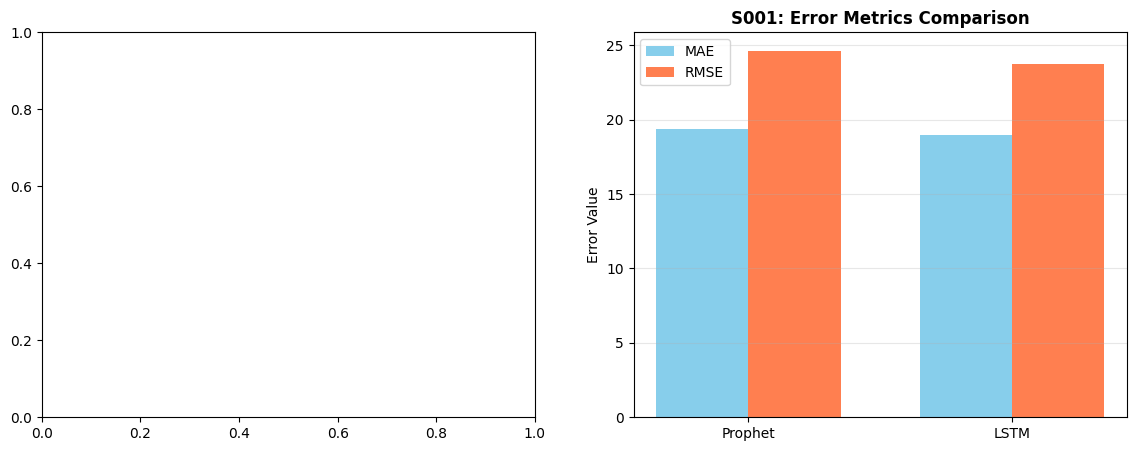


===== S001 ERROR EVALUATION =====
Prophet - MAE: 19.3872, RMSE: 24.6381
LSTM    - MAE: 18.9534, RMSE: 23.7620


In [49]:
# Simple error evaluation for S001

# 1. GET PROPHET PREDICTIONS
prophet_model = fitted_models['Store_S001']
prophet_forecast = prophet_model.predict(prophet_model.make_future_dataframe(periods=0))
prophet_pred = prophet_forecast[['yhat']].values.flatten()

# 2. GET LSTM PREDICTIONS
lstm_model = trained_models['S001']
lstm_pred_scaled = lstm_model.predict(X_S001_lstm, verbose=0)
lstm_pred = S001_scaler.inverse_transform(lstm_pred_scaled).reshape(-1)

# 3. GET ACTUAL VALUES
y_actual = S001_scaler.inverse_transform(y_S001_lstm.reshape(-1, 1)).reshape(-1)

# 4. CALCULATE METRICS
from sklearn.metrics import mean_absolute_error, mean_squared_error

prophet_mae = mean_absolute_error(y_actual[:len(prophet_pred)], prophet_pred[:len(y_actual)])
prophet_rmse = np.sqrt(mean_squared_error(y_actual[:len(prophet_pred)], prophet_pred[:len(y_actual)]))

lstm_mae = mean_absolute_error(y_actual, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(y_actual, lstm_pred))

# # 5. PLOT
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Right: Error Metrics Comparison
models = ['Prophet', 'LSTM']
mae_values = [prophet_mae, lstm_mae]
rmse_values = [prophet_rmse, lstm_rmse]

x = np.arange(len(models))
width = 0.35

axes[1].bar(x - width/2, mae_values, width, label='MAE', color='skyblue')
axes[1].bar(x + width/2, rmse_values, width, label='RMSE', color='coral')
axes[1].set_ylabel('Error Value')
axes[1].set_title('S001: Error Metrics Comparison', fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models)
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

# plt.tight_layout()
plt.show()

# Print metrics
print("\n===== S001 ERROR EVALUATION =====")
print(f"Prophet - MAE: {prophet_mae:.4f}, RMSE: {prophet_rmse:.4f}")
print(f"LSTM    - MAE: {lstm_mae:.4f}, RMSE: {lstm_rmse:.4f}")

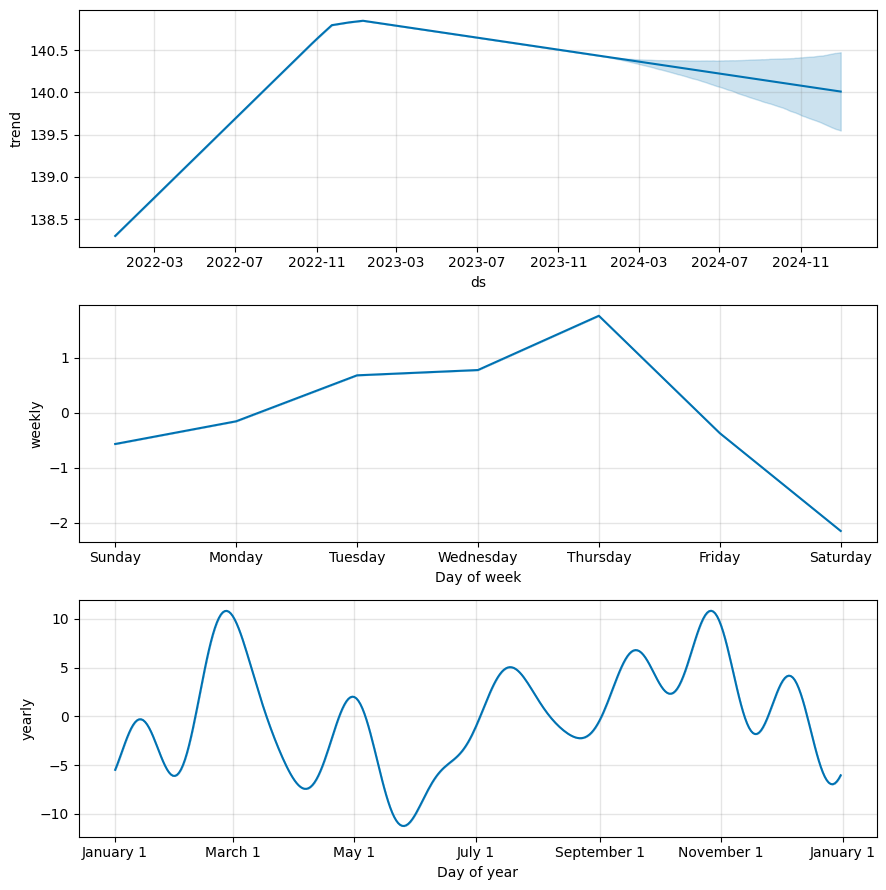

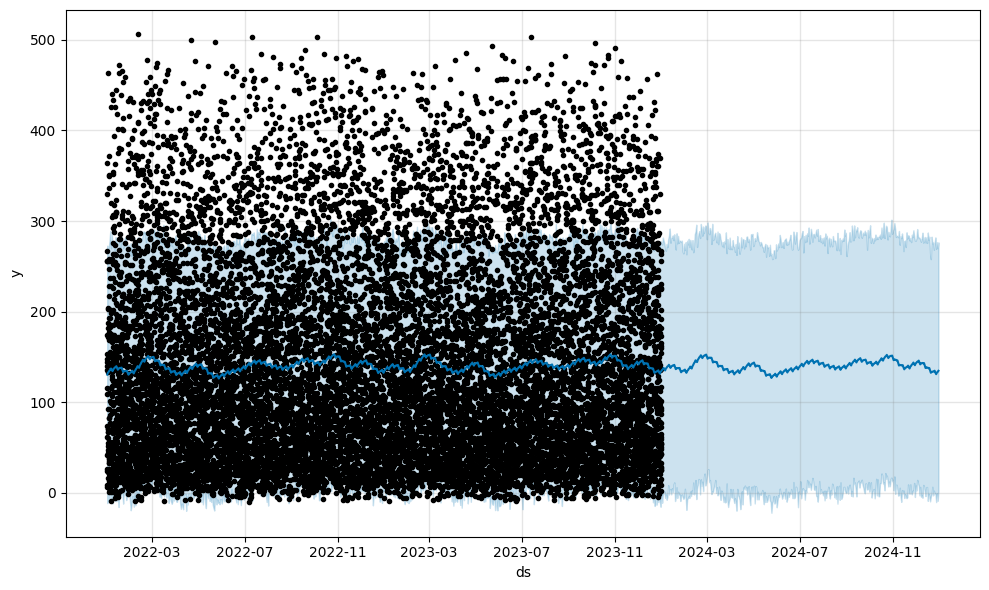

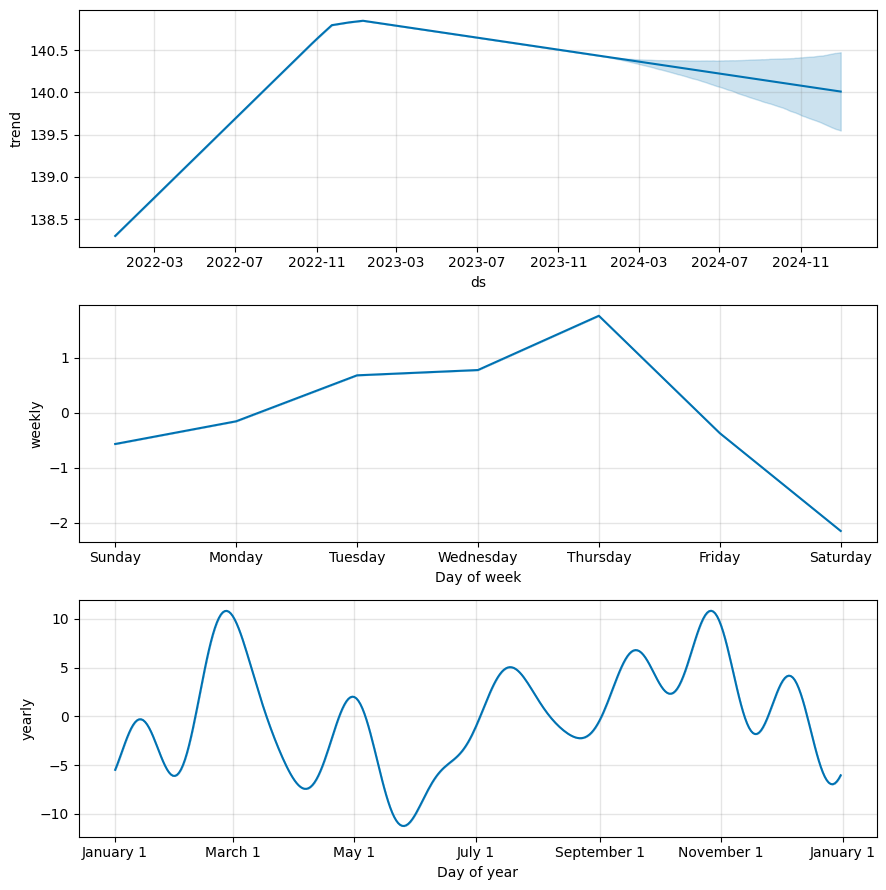

In [50]:
store1 = fitted_models['Store_S001']
# # forecasting future values for prophet
store1_data = store1.make_future_dataframe(periods=365, freq='D')
forecast_prophet = store1.predict(store1_data)

# #plot prophet forecast
fig = store1.plot(forecast_prophet)
store1.plot_components(forecast_prophet)

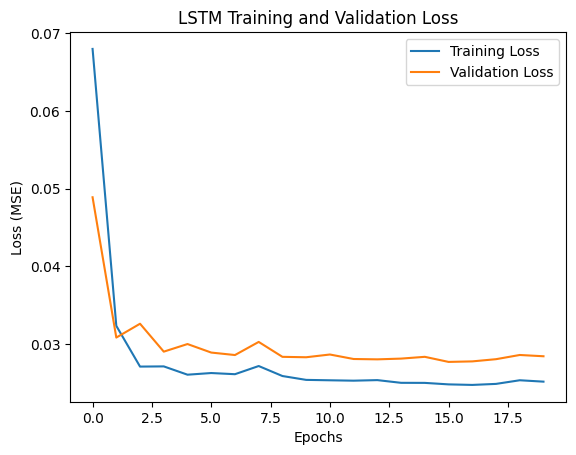

In [51]:
#plotting LSTM metrics 
plt.plot(S001_metrics.history['loss'], label='Training Loss')
plt.plot(S001_metrics.history['val_loss'], label='Validation Loss')
plt.title('LSTM Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.show()

In [52]:
S001_lstm_model = trained_models['S001']

# Reshape train and test data for LSTM prediction (need 3D: [samples, time_steps, features])
def reshape_for_prediction(dataframe):
    """Reshape 2D dataframe to 3D LSTM input without pairing with y"""
    X_raw = dataframe.values  # Shape: (total_rows, num_features)
    num_samples = len(X_raw) - TIME_STEPS
    
    X_lstm = np.lib.stride_tricks.sliding_window_view(
        X_raw, 
        window_shape=(TIME_STEPS, X_raw.shape[1])
    ).squeeze(axis=1)[:num_samples]
    
    return X_lstm

# S001_train_y = S001_train_df['y']
# S001_train_df = S001_train_df.drop(columns=['y'])

S001_test_y = S001_test_df['y']
S001_test_df = S001_test_df.drop(columns=['y'])


X_S001_train_reshaped = reshape_for_prediction(S001_train_df)
X_S001_test_reshaped = reshape_for_prediction(S001_test_df)


In [53]:
lstm_pred_train = S001_lstm_model.predict(X_S001_train_reshaped, verbose=0)
lstm_pred_test = S001_lstm_model.predict(X_S001_test_reshaped, verbose=0)

# Inverse transform predictions
train_predict_lstm = S001_scaler.inverse_transform(lstm_pred_train)
test_predict_lstm = S001_scaler.inverse_transform(lstm_pred_test)

# # Inverse transform actual scaled values
Y_train_lstm = S001_scaler.inverse_transform(S001_train_y_scaled)
Y_test_lstm = S001_scaler.inverse_transform(S001_test_y_scaled)

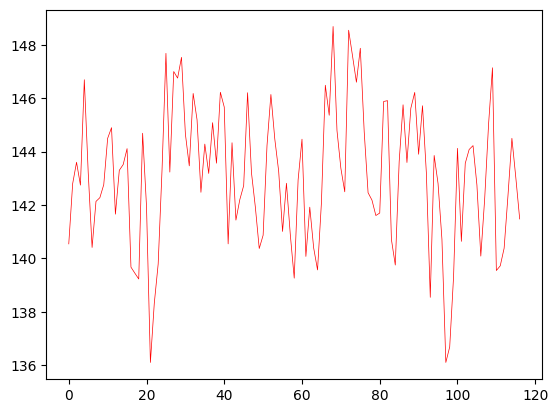

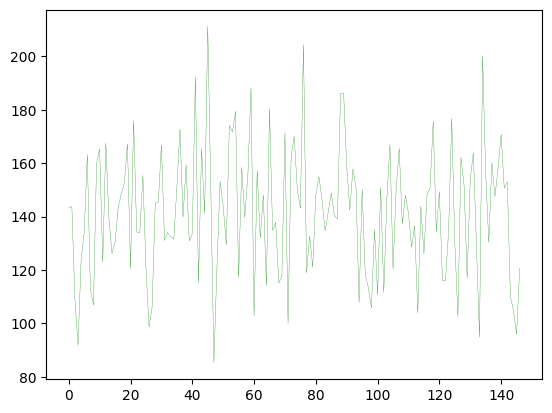

In [54]:


plt.plot(test_predict_lstm, lw='0.5' , color='red')
plt.show()
plt.plot(Y_test_lstm, lw='0.2' , color='green')
plt.show()

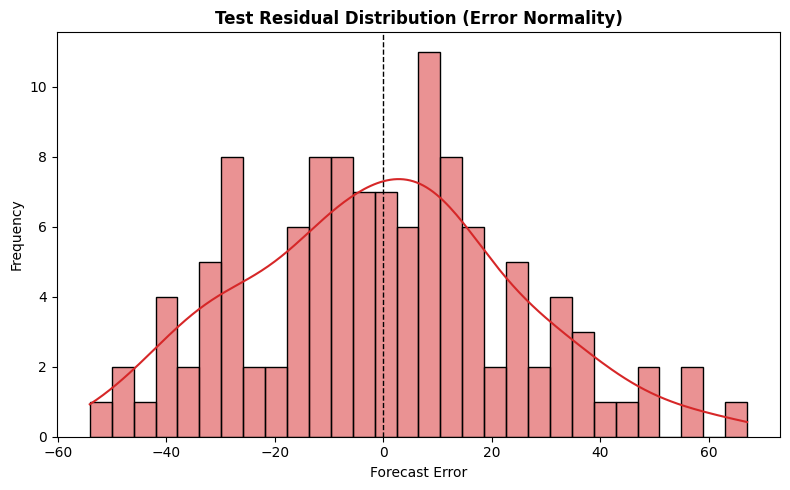

<Figure size 640x480 with 0 Axes>

In [55]:
# --- 4. Error Distribution ---
Y_train_lstm = S001_scaler.inverse_transform(y_S001_lstm.reshape(-1, 1)).reshape(-1)
train_predict_lstm = S001_scaler.inverse_transform(lstm_pred_train).reshape(-1)
res_train = Y_train_lstm - train_predict_lstm

Y_test_lstm = S001_scaler.inverse_transform(S001_test_y_scaled[TIME_STEPS:].reshape(-1, 1)).reshape(-1)
test_predict_lstm = S001_scaler.inverse_transform(lstm_pred_test).reshape(-1)
res_test = Y_test_lstm - test_predict_lstm

fig, ax = plt.subplots(1, 1, figsize=(8, 5))

sns.histplot(x=res_test, kde=True, bins=30, color="#d62728", ax=ax)
ax.axvline(x=0, color="black", linestyle="--", linewidth=1)
ax.set_title("Test Residual Distribution (Error Normality)", fontsize=12, fontweight="bold")
ax.set_xlabel("Forecast Error")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()
plt.tight_layout()
plt.show()

In [56]:
print("\n===== S001 ERROR EVALUATION =====")
print(f"Prophet - MAE: {prophet_mae:.4f}, RMSE: {prophet_rmse:.4f}")
print(f"LSTM    - MAE: {lstm_mae:.4f}, RMSE: {lstm_rmse:.4f}")


===== S001 ERROR EVALUATION =====
Prophet - MAE: 19.3872, RMSE: 24.6381
LSTM    - MAE: 18.9534, RMSE: 23.7620
